**Imports**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

**Load Dataset**

In [2]:
path = "/kaggle/input/datasets/miadul/house-price-prediction-dataset/house_price_50k.csv"

df = pd.read_csv(path)

print(df.shape)
display(df.head())

(50000, 19)


,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,location,income_level,price
0,1360,6,2,2,9,10,0,0,1,0,1,0,1,0,6.939333,7242,premium,low,5.952493e+05
1,4272,5,2,3,24,8,1,0,0,1,1,1,1,0,0.400918,7729,low,low,1.571208e+06
2,3592,1,4,3,4,20,0,1,1,1,0,1,0,1,6.292386,1081,premium,mid,1.379943e+06
3,966,5,2,2,6,14,1,0,0,0,0,1,1,0,8.964112,8912,medium,low,4.367819e+05
4,4926,4,3,1,18,9,0,0,0,0,1,0,1,1,2.843309,8146,low,mid,1.792425e+06


**Data Cleaning**

In [3]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.dropna(subset=["price"])
df = df[df["price"] > 0]

print("Shape after cleaning:", df.shape)

area                    0
bedrooms                0
bathrooms               0
floors                  0
age                     0
distance                0
garage                  0
parking                 0
garden                  0
security                0
school_nearby           0
hospital_nearby         0
shopping_mall_nearby    0
public_transport        0
crime_rate              0
population_density      0
location                0
income_level            0
price                   0
dtype: int64
Duplicates: 0
Shape after cleaning: (50000, 19)


**EDA**

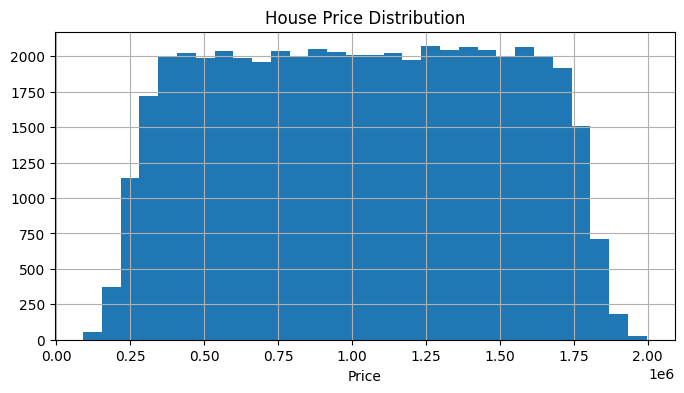

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,price
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,5.000000e+04
mean,2752.970540,3.496040,2.498040,1.997060,19.573740,14.968700,0.500540,0.497300,0.500280,0.496220,0.501100,0.498320,0.498320,0.500040,5.006444,5065.94598,1.030261e+06
std,1297.148134,1.712146,1.117704,0.815368,11.552502,8.363714,0.500005,0.499998,0.500005,0.499991,0.500004,0.500002,0.500002,0.500005,2.876776,2864.34322,4.580199e+05
min,500.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000311,100.00000,9.090069e+04
25%,1630.000000,2.000000,1.000000,1.000000,10.000000,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.523018,2575.00000,6.357375e+05
50%,2756.000000,3.000000,2.000000,2.000000,20.000000,15.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,5.022946,5060.50000,1.031763e+06
75%,3872.000000,5.000000,3.000000,3.000000,30.000000,22.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.479632,7543.00000,1.423102e+06
max,4999.000000,6.000000,4.000000,3.000000,39.000000,29.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,9.999869,9999.00000,1.996474e+06


In [4]:
df["price"].hist(bins=30, figsize=(8, 4))
plt.title("House Price Distribution")
plt.xlabel("Price")
plt.show()

display(df.describe())

**Separate Features and Target**

In [5]:
X = df.drop("price", axis=1)
y = df["price"]

numeric_cols = X.select_dtypes(include=np.number).columns
categorical_cols = X.select_dtypes(exclude=np.number).columns

print("Numerical features:", list(numeric_cols))
print("Categorical features:", list(categorical_cols))

Numerical features: ['area', 'bedrooms', 'bathrooms', 'floors', 'age', 'distance', 'garage', 'parking', 'garden', 'security', 'school_nearby', 'hospital_nearby', 'shopping_mall_nearby', 'public_transport', 'crime_rate', 'population_density']
Categorical features: ['location', 'income_level']


**Test tran split**

In [6]:
price_groups = pd.qcut(y, q=10, labels=False, duplicates="drop")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=price_groups
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (40000, 18)
Testing data: (10000, 18)


**Preprocessing**

In [7]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

**Define Models**

In [8]:
from sklearn.linear_model import Ridge

polynomial_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler())
    ]), numeric_cols),

    ("cat", categorical_transformer, categorical_cols)
])

models = {
    # 1. Ridge Regression (L2 Regularized Linear Regression)
    "Linear Regression": Pipeline([
        ("prep", preprocessor),
        ("model", Ridge(alpha=1.0))
    ]),

    # 2. Ridge Polynomial Regression (Prevents feature explosion overfitting)
    "Polynomial Regression": Pipeline([
        ("prep", polynomial_preprocessor),
        ("model", Ridge(alpha=10.0))
    ]),

    # 3. Regularized Decision Tree
    "Decision Tree": Pipeline([
        ("prep", preprocessor),
        ("model", DecisionTreeRegressor(
            max_depth=6, 
            min_samples_leaf=30, 
            min_samples_split=60, 
            random_state=42
        ))
    ]),

    # 4. Regularized Random Forest
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=150,
            max_depth=8,
            min_samples_leaf=20,
            min_samples_split=40,
            max_features='sqrt', # Randomly subsamples features per tree
            random_state=42,
            n_jobs=-1
        ))
    ]),

    # 5. Regularized XGBoost
    "XGBoost": Pipeline([
        ("prep", preprocessor),
        ("model", XGBRegressor(
            n_estimators=200,        # Slightly more trees since learning rate dropped
            max_depth=3,             # Shallow trees (from 4) are best for boosting
            learning_rate=0.02,      # Slower pacing (from 0.03) for safer steps
            subsample=0.7,           # More aggressive row shuffling (from 0.8)
            colsample_bytree=0.7,    # More aggressive column shuffling (from 0.8)
            reg_alpha=1.0,           # Stronger L1 penalty (from 0.1) to drop weak features
            reg_lambda=10.0,         # Stronger L2 penalty (from 1.0) to smooth leaf weights
            random_state=42,
            n_jobs=-1
        ))
    ])
}

**Train models**

In [9]:
results = []
trained_models = {}

for name, model in models.items():

    print("Training:", name)

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    results.append({
        "Model": name,
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Test R2": r2_score(y_test, test_pred)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("Test RMSE")

display(results_df.round(3))

Training: Linear Regression
Training: Polynomial Regression
Training: Decision Tree
Training: Random Forest
Training: XGBoost


,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Test R2
0,Linear Regression,15936.379,16098.451,19952.936,20134.281,0.998
1,Polynomial Regression,15917.721,16176.958,19935.422,20225.565,0.998
4,XGBoost,40044.608,40704.313,50091.936,50760.944,0.988
2,Decision Tree,43078.741,44578.272,53669.759,55587.748,0.985
3,Random Forest,140424.244,143200.863,171949.183,175572.373,0.853


**GridSearch CV**

In [10]:
tuning_grids = {
    "Random Forest": {
        "model__max_depth": [10, 15, 20],          # Stop trees from growing infinitely deep
        "model__min_samples_split": [20, 50],       # Require more samples to split a node
        "model__min_samples_leaf": [10, 20],        # Force leaf nodes to generalize broader groups
        "model__max_features": [0.7, "sqrt"]        # Randomly subset features per tree to reduce variance
    },

    "XGBoost": {
        "model__max_depth": [4, 5, 6],              # Keep individual trees shallow
        "model__learning_rate": [0.01, 0.05],       # Slower learning rate for better generalization
        "model__subsample": [0.8],                  # Train each tree on 80% of data randomly
        "model__colsample_bytree": [0.8],           # Use 80% of features per tree
        "model__n_estimators": [200, 300]           # More trees with a lower learning rate
    }
}

for name, params in tuning_grids.items():

    print("Tuning:", name)

    grid = GridSearchCV(
        estimator=models[name],
        param_grid=params,
        scoring="neg_root_mean_squared_error",
        cv=3,
        n_jobs=-1
    )

    grid.fit(X_train, y_train)
    trained_models[name] = grid.best_estimator_

    print("Best parameters:", grid.best_params_)
    print("Best CV RMSE:", round(-grid.best_score_, 3))

Tuning: Random Forest
Best parameters: {'model__max_depth': 20, 'model__max_features': 0.7, 'model__min_samples_leaf': 10, 'model__min_samples_split': 20}
Best CV RMSE: 30425.727
Tuning: XGBoost
Best parameters: {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 300, 'model__subsample': 0.8}
Best CV RMSE: 21133.26


**Evaluate all trained models**

In [11]:
final_results = []

for name, model in trained_models.items():

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    final_results.append({
        "Model": name,
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "Test R2": r2_score(y_test, test_pred)
    })

final_df = pd.DataFrame(final_results).sort_values("Test RMSE")

display(final_df.round(3))

best_name = final_df.iloc[0]["Model"]
best_model = trained_models[best_name]

print("Best model:", best_name)

,Model,Train RMSE,Test RMSE,Test MAE,Test R2
0,Linear Regression,19952.936,20134.281,16098.451,0.998
1,Polynomial Regression,19935.422,20225.565,16176.958,0.998
4,XGBoost,19945.108,21172.881,16956.536,0.998
3,Random Forest,23374.032,29417.156,23617.049,0.996
2,Decision Tree,53669.759,55587.748,44578.272,0.985


Best model: Linear Regression


**Save the best model**

In [12]:
with open("/kaggle/working/best_house_price_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

final_df.to_csv(
    "/kaggle/working/model_comparison.csv",
    index=False
)

print("Model saved successfully!")

Model saved successfully!


**Load and test model**

In [13]:
with open("/kaggle/working/best_house_price_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

sample = X_test.iloc[[0]]

print("Actual price:", y_test.iloc[0])
print("Predicted price:", loaded_model.predict(sample)[0])

Actual price: 593085.067136711
Predicted price: 596209.5427090946
